In [2]:
import pandas as pd 
import matplotlib.pyplot as plt

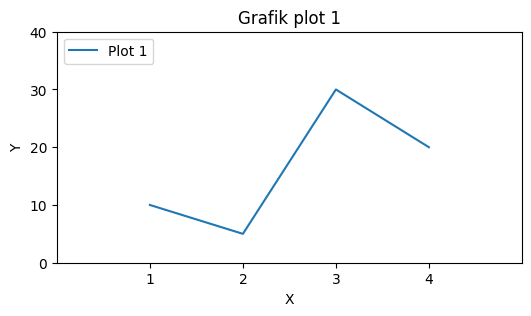

In [3]:
plt.figure(figsize=(6, 3))
plt.plot([1,2,3,4], [10,5,30,20], label = "Plot 1") # (data x , data y)
plt.xticks([1,2,3,4])
plt.yticks([0, 10, 20, 30, 40])
plt.xlim(0,5)
plt.ylim(0,40)
plt.ylabel("Y")
plt.xlabel("X")
plt.title("Grafik plot 1")
plt.legend(loc = "upper left")
plt.show()

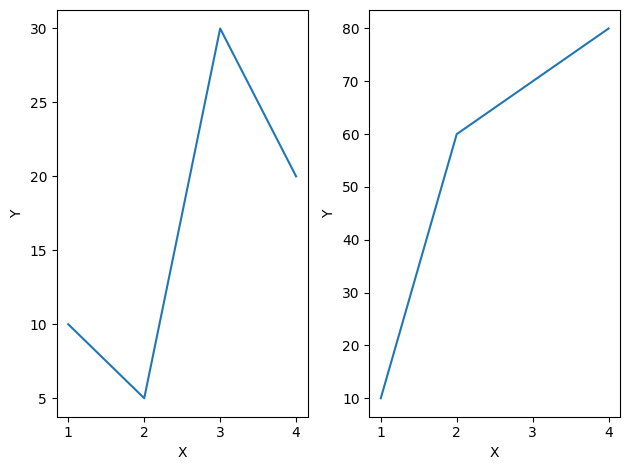

In [4]:
plt.subplot(121) # (baris, kolom, letak plot)
plt.plot([1,2,3,4], [10,5,30,20], label = "Plot 1")
plt.xlabel("X")
plt.ylabel("Y")

plt.subplot(122)
plt.plot([1,2,3,4], [10,60,70,80], label = "Plot 2")
plt.xlabel("X")
plt.ylabel("Y")

plt.tight_layout()
plt.show()

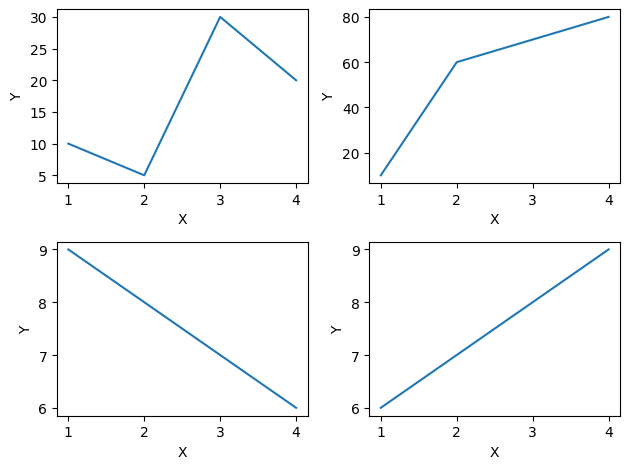

In [5]:
plt.subplot(221) # (baris, kolom, letak plot)
plt.plot([1,2,3,4], [10,5,30,20], label = "Plot 1")
plt.xlabel("X")
plt.ylabel("Y")

plt.subplot(222)
plt.plot([1,2,3,4], [10,60,70,80], label = "Plot 2")
plt.xlabel("X")
plt.ylabel("Y")

plt.subplot(223)
plt.plot([1,2,3,4], [9,8,7,6], label = "Plot 3")
plt.xlabel("X")
plt.ylabel("Y")

plt.subplot(224)
plt.plot([1,2,3,4], [6,7,8,9], label = "Plot 4")
plt.xlabel("X")
plt.ylabel("Y")

plt.tight_layout()
plt.show()

In [6]:
csv = pd.read_csv("penyakit_jantung.csv")
source = csv[["sex", "age", "cp", "trestbps", "chol"]]
source.head()

,sex,age,cp,trestbps,chol
0,female,63,3,145,233
1,female,37,2,130,250
2,male,41,1,130,204
3,female,56,1,120,236
4,male,57,0,120,354


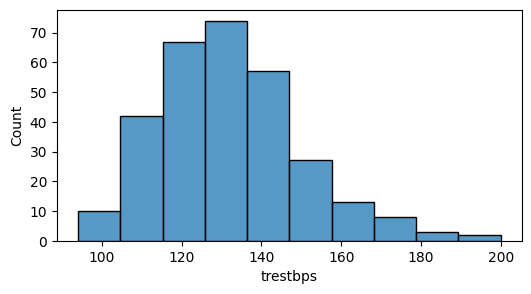

In [7]:
import seaborn as sns

plt.figure(figsize=(6,3))
sns.histplot(x = "trestbps", data = source, bins = 10)
plt.show()

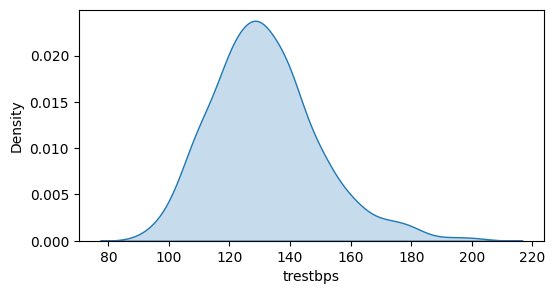

In [8]:
plt.figure(figsize=(6,3))
sns.kdeplot(x = "trestbps", data = source, fill=True)
plt.show()

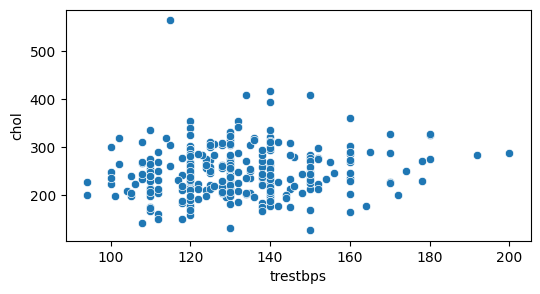

In [9]:
plt.figure(figsize=(6,3))
sns.scatterplot(x = "trestbps", y = "chol", data = source)
plt.show()

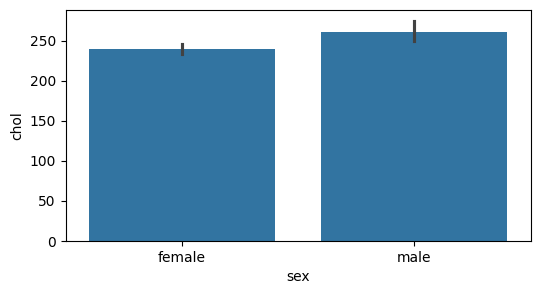

In [10]:
plt.figure(figsize=(6,3))
sns.barplot(x = "sex", y = "chol", data = source)
plt.show()

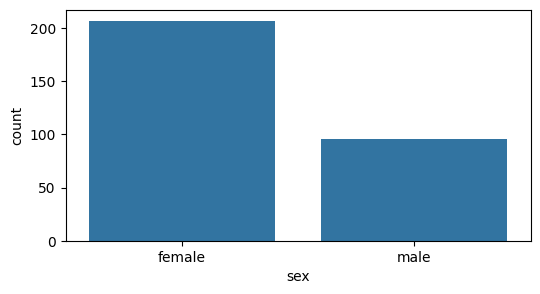

In [11]:
plt.figure(figsize=(6,3))
sns.countplot(x = "sex", data = source)
plt.show()

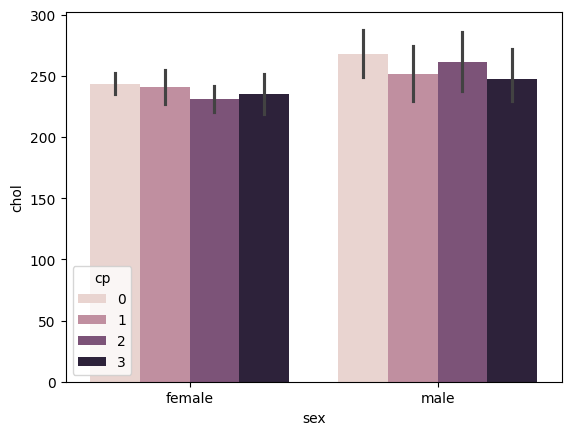

In [12]:
sns.barplot(x = "sex", y = "chol", hue = "cp", data = source)
plt.show()

PANDAS BONUS

In [13]:
source

,sex,age,cp,trestbps,chol
0,female,63,3,145,233
1,female,37,2,130,250
2,male,41,1,130,204
3,female,56,1,120,236
4,male,57,0,120,354
...,...,...,...,...,...
298,male,57,0,140,241
299,female,45,3,110,264
300,female,68,0,144,193
301,female,57,0,130,131


In [14]:
group_value_count = source.groupby("sex")["trestbps"].value_counts()
group_sum = source.groupby("sex")["trestbps"].sum()
group_mean = source.groupby("sex")["trestbps"].mean()
group_count = source.groupby("sex")["trestbps"].count()

In [15]:
group_value_count = source.groupby(["sex", "age"])[["trestbps", "chol"]].sum()
group_value_count

trestbps  chol
sex    age                
female 29        130   204
       34        118   182
       35        368   672
       37        130   250
       38        396   581
...              ...   ...
male   68        120   211
       69        140   239
       71        382   716
       74        120   269
       76        140   197

[73 rows x 2 columns]

sex
female    130.946860
male      133.083333
Name: trestbps, dtype: float64
Index(['female', 'male'], dtype='object', name='sex')
[130.9468599  133.08333333]


<Axes: xlabel='sex'>

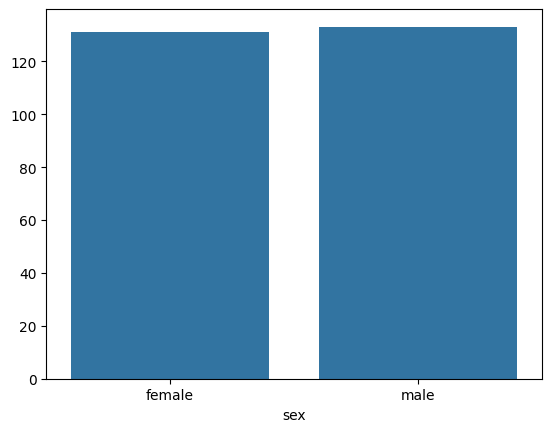

In [16]:
# cara 1

group_mean = source.groupby("sex")["trestbps"].mean()
print(group_mean)
print(group_mean.index)
print(group_mean.values)

sns.barplot(x = group_mean.index, y = group_mean.values)

<Axes: xlabel='sex', ylabel='trestbps'>

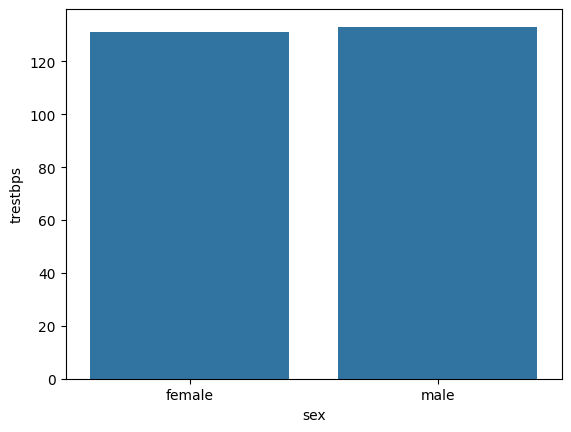

In [17]:
# cara 2

mean_dataframe = group_mean.reset_index() # reset_index mengubah groupby menjadi dataframe
sns.barplot(x = "sex", y = "trestbps", data = mean_dataframe)

In [18]:
# menambah kolom baru pada hasil dataframe reset_index

mean_dataframe = group_mean.reset_index()
mean_dataframe["sum"] = group_sum.values
mean_dataframe.columns = ["sex", "mean", "sum"]
mean_dataframe

,sex,mean,sum
0,female,130.946860,27106
1,male,133.083333,12776


In [19]:
pivot = source.pivot_table(index = "sex", columns = "age", values = "chol")
pivot = pivot.fillna(0)
pivot_to_groupby = pivot.unstack()

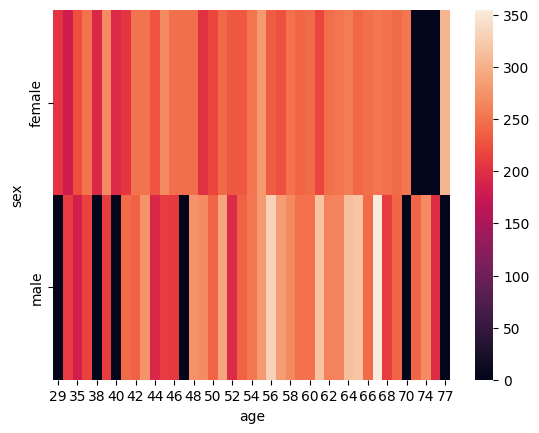

In [20]:
sns.heatmap(pivot)
plt.show()

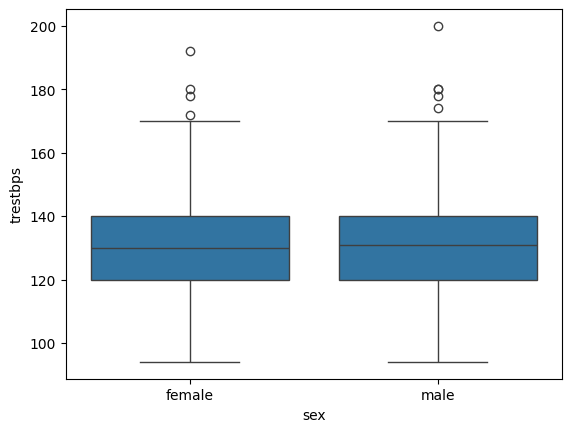

In [21]:
sns.boxplot(x = "sex", y = "trestbps", data = source)
plt.show()

In [22]:
pivot

age,29,34,35,37,38,39,40,41,42,43,...,65,66,67,68,69,70,71,74,76,77
sex,,,,,,,,,,,,,,,,,,,,,
female,204.0,182.0,224.0,250.0,193.666667,270.0,196.333333,205.166667,250.0,250.0,...,240.25,247.0,252.833333,248.0,244.0,252.5,0.000000,0.0,0.0,304.0
male,0.0,210.0,183.0,215.0,0.000000,209.5,0.000000,244.000000,237.0,277.0,...,317.75,244.0,354.666667,211.0,239.0,0.0,238.666667,269.0,197.0,0.0


In [23]:
pivot_to_groupby = pivot.unstack()
pivot_to_groupby

age  sex   
29   female    204.0
     male        0.0
34   female    182.0
     male      210.0
35   female    224.0
               ...  
74   male      269.0
76   female      0.0
     male      197.0
77   female    304.0
     male        0.0
Length: 82, dtype: float64

In [24]:
source

,sex,age,cp,trestbps,chol
0,female,63,3,145,233
1,female,37,2,130,250
2,male,41,1,130,204
3,female,56,1,120,236
4,male,57,0,120,354
...,...,...,...,...,...
298,male,57,0,140,241
299,female,45,3,110,264
300,female,68,0,144,193
301,female,57,0,130,131


In [29]:
source["sex"].unique()

array(['female', 'male'], dtype=object)

In [37]:
group_mean = source.groupby("sex")["trestbps"].sum()
print(group_mean.idxmax())
print(group_mean.idxmin())

female
male


<Axes: xlabel='sex'>

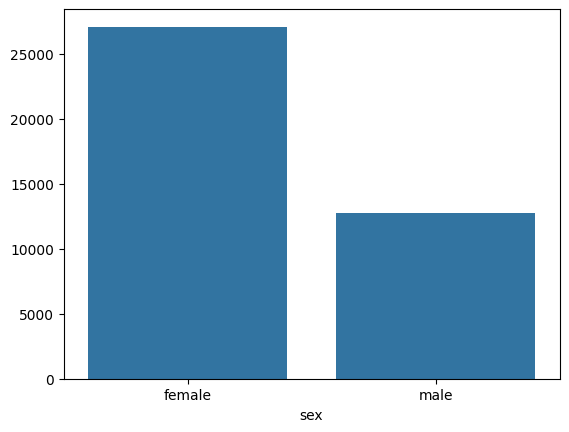

In [34]:
sns.barplot(x = group_mean.index, y = group_mean.values)